In [1]:
import sys, os
print(sys.executable)

/Users/andresho/Desktop/C-MARL/venv/bin/python3.11


In [2]:
import numpy as np
import time
from dataclasses import dataclass
import tensorflow as tf

In [3]:
sys.path.insert(0, os.path.abspath("../.."))   # sandboxes/test2 -> project root
from game_environments.ToyGame import ToyGame

from core.agents import build_agents
from core.rollout import run_episodes, take_belief_step
from algorithms.gda_baseline import train
# Factored (N-sigmoid, amortized-hidden) belief -- this project's own variant,
# meant to generalize to k>1 adversaries. For the faithful EIR-MAPPO
# reproduction (N+1-way categorical belief), swap this import for
# `from beliefs import categorical_eirmappo as belief_module`, or just run
# experiments/run_baseline.py directly.
from beliefs import categorical_eirmappo as belief_module
from beliefs import factored_sigmoid as belief_module_2
from checks import belief_io

tf.random.set_seed(0)
np.random.seed(0)

cfg = ToyGame(20, ep_len=10)
agents = build_agents(cfg, belief_module, hidden=128)
belief_step = take_belief_step(agents, belief_module)
print("TF", tf.__version__, "| Config:", cfg)

print("\nBelief:")
output = belief_io.check_belief(belief_module)
step_output = belief_io.check_belief_step(belief_module)

TF 2.14.0 | Config: <game_environments.ToyGame.ToyGame object at 0x10cf92c50>

Belief:
feats   (8, 5, 6)
belief  (8, 5, 3)   range [0.249, 0.440]
[[0.35378012 0.31387568 0.33234414]
 [0.38230127 0.27391878 0.34377995]
 [0.44031265 0.28048164 0.27920568]
 [0.41987535 0.2850728  0.2950519 ]
 [0.37536997 0.25741366 0.3672164 ]]
policy_input  (8, 3)
h_next        (8, 128)
belief_probs  (8, 3)
[0.34383056 0.30423617 0.35193333]


In [4]:
hist = train(
    ToyGame, agents, belief_step, belief_module,
    B=20, n_iters=2000, log_every=100,
    team_interval=10
)


iter   100 | reward(adv) 0.527 | reward(clean) 0.578 | belief acc 0.275 | 3s
iter   200 | reward(adv) 0.260 | reward(clean) 0.620 | belief acc 0.250 | 5s
iter   300 | reward(adv) 0.575 | reward(clean) 0.458 | belief acc 0.600 | 6s
iter   400 | reward(adv) 0.675 | reward(clean) 0.625 | belief acc 0.400 | 8s
iter   500 | reward(adv) 0.663 | reward(clean) 0.658 | belief acc 0.600 | 10s
iter   600 | reward(adv) 0.450 | reward(clean) 0.630 | belief acc 0.500 | 12s
iter   700 | reward(adv) 0.120 | reward(clean) 0.620 | belief acc 0.310 | 14s
iter   800 | reward(adv) 0.750 | reward(clean) 0.550 | belief acc 0.520 | 16s
iter   900 | reward(adv) 0.550 | reward(clean) 0.575 | belief acc 0.385 | 18s
iter  1000 | reward(adv) 0.622 | reward(clean) 0.482 | belief acc 0.345 | 19s
iter  1100 | reward(adv) 0.140 | reward(clean) 0.500 | belief acc 0.323 | 21s
iter  1200 | reward(adv) 0.283 | reward(clean) 0.636 | belief acc 0.650 | 23s
iter  1300 | reward(adv) 0.950 | reward(clean) 0.500 | belief acc 0.

In [5]:
record = run_episodes(ToyGame(1000), agents, belief_step)


In [6]:
print(record['reward'].shape)
total_reward = np.sum(record['reward'], axis=1)
avg_reward = np.mean(total_reward)
avg_reward2 = np.mean(record['reward'])
print(avg_reward)
print(avg_reward2)

(1000, 10)
6.747
0.6747


In [7]:
print(hist.keys())

dict_keys(['reward_adv', 'reward_clean', 'belief_acc'])


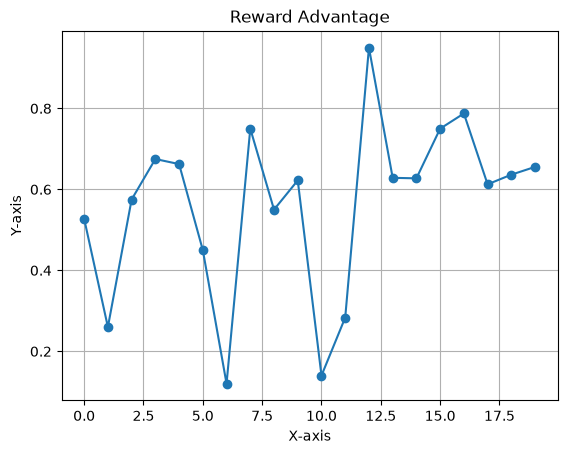

In [8]:
import matplotlib.pyplot as plt
plt.plot(range(len(hist['reward_adv'])),hist['reward_adv'], marker='o')

# Labels and title
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Reward Advantage")

# Optional: grid
plt.grid(True)

# Show plot
plt.show()

In [9]:
from evaluation.honest_eval import evaluate_robustness
w_before = agents.policy.get_weights()[0].copy()
eval_hist = evaluate_robustness(cfg, agents, belief_step, n_iters=400, log_every=100)
w_after = agents.policy.get_weights()[0]
print("policy frozen:", np.allclose(w_before, w_after))


attack iter   100 | reward(adv) 0.057 | reward(clean) 0.669
attack iter   200 | reward(adv) 0.062 | reward(clean) 0.642
attack iter   300 | reward(adv) 0.025 | reward(clean) 0.667
attack iter   400 | reward(adv) 0.011 | reward(clean) 0.664
policy frozen: True


In [10]:
eval_hist.keys()

dict_keys(['curve', 'robust_reward_mean', 'robust_reward_min', 'clean_reward'])

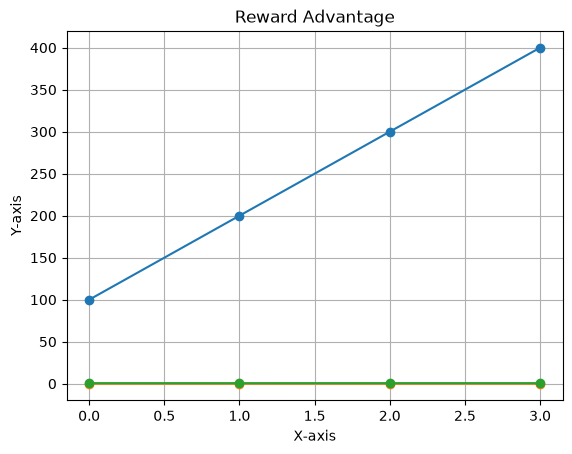

In [11]:
plt.plot(range(len(eval_hist['curve'])),eval_hist['curve'], marker='o')

# Labels and title
plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Reward Advantage")

# Optional: grid
plt.grid(True)

# Show plot
plt.show()

In [15]:
# and: what does the trained team get on clean episodes, right now?
ev = run_episodes(cfg, agents, belief_step)
ep_r = ev['reward'].mean(axis=1)
clean = ep_r[ev['theta'][:,0,:].sum(axis=1)==0].mean()
print("clean reward with trained agents:", clean)   # should be ~0.99


clean reward with trained agents: 0.485942
